## **Section 0: Imports & Setup**

In [ ]:
import json
import random
import os
import time
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## **Section 1: Dataset Loading & Preparation (10 Marks)**
### Task 1.1: Data Ingestion & Splitting [5 Marks]

In [ ]:
import urllib.request
import os
import numpy as np

# Load real rainfall data safely
data_path = '/rainfall_dataset.npy'

if not os.path.exists(data_path):
    print("Error: rainfall_dataset.npy not found. Please ensure it is in the same directory.")
else:
    # Use mmap_mode='r' to prevent loading the entire dataset into memory at once
    data = np.load(data_path, mmap_mode='r')  # (N, 20, 1, 64, 64)

    # Split (80% Train, 10% Val, 10% Test)
    total_samples = len(data)
    train_end = int(0.8 * total_samples)
    val_end = int(0.9 * total_samples)

    train_data = data[:train_end]
    val_data = data[train_end:val_end]
    test_data = data[val_end:]

    print(f"Train shape: {train_data.shape}")
    print(f"Val shape: {val_data.shape}")
    print(f"Test shape: {test_data.shape}")

Train shape: (1707, 20, 1, 64, 64)
Val shape: (213, 20, 1, 64, 64)
Test shape: (214, 20, 1, 64, 64)


### Task 1.2: Custom Dataset & Visualization [5 Marks]

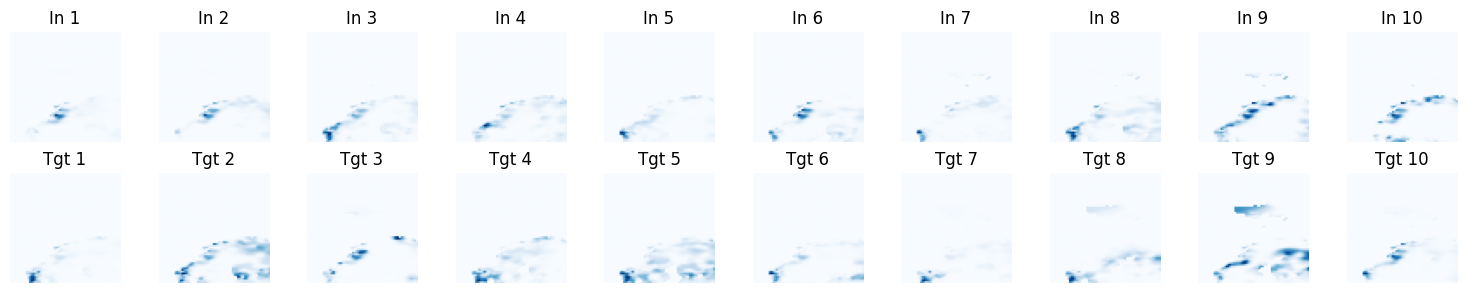

In [ ]:
class RainfallDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Load sample into memory
        sample = self.data[idx].copy()

        # Normalize rainfall: clip at 100mm/day and normalize to [0, 1]
        sample = np.clip(sample, 0, 100) / 100.0
        sample = sample.astype(np.float32)

        input_seq = torch.tensor(sample[:10])
        target_seq = torch.tensor(sample[10:])
        return input_seq, target_seq

if 'data' in locals():
    train_dataset = RainfallDataset(train_data)
    val_dataset = RainfallDataset(val_data)
    test_dataset = RainfallDataset(test_data)

    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

    # Visualization
    inputs, targets = train_dataset[0]
    fig, axes = plt.subplots(2, 10, figsize=(15, 3))
    for t in range(10):
        axes[0, t].imshow(inputs[t, 0].numpy(), cmap='Blues')
        axes[0, t].set_title(f"In {t+1}")
        axes[0, t].axis('off')

        axes[1, t].imshow(targets[t, 0].numpy(), cmap='Blues')
        axes[1, t].set_title(f"Tgt {t+1}")
        axes[1, t].axis('off')
    plt.tight_layout()
    plt.show()

## **Section 2: ConvLSTM Architecture (15 Marks)**
### Task 2.1: ConvLSTM Cell Module [7 Marks]

In [ ]:
class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels, kernel_size):
        super().__init__()
        self.hidden_channels = hidden_channels
        padding = kernel_size // 2

        self.conv = nn.Conv2d(
            in_channels=input_channels + hidden_channels,
            out_channels=4 * hidden_channels,
            kernel_size=kernel_size,
            padding=padding,
            bias=True
        )

    def forward(self, x_t, h_prev, c_prev):
        combined = torch.cat([x_t, h_prev], dim=1)
        gates = self.conv(combined)
        i, f, c_tilde, o = gates.chunk(4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        c_tilde = torch.tanh(c_tilde)
        o = torch.sigmoid(o)

        c_t = f * c_prev + i * c_tilde
        h_t = o * torch.tanh(c_t)
        return h_t, c_t

    def init_hidden(self, batch_size, height, width, device):
        return (torch.zeros(batch_size, self.hidden_channels, height, width, device=device),
                torch.zeros(batch_size, self.hidden_channels, height, width, device=device))

# Verify
cell = ConvLSTMCell(1, 64, 3)
dummy_x = torch.randn(2, 1, 64, 64)
dummy_h, dummy_c = cell.init_hidden(2, 64, 64, 'cpu')
h_out, c_out = cell(dummy_x, dummy_h, dummy_c)
print(f"ConvLSTMCell h_out shape: {h_out.shape}")

ConvLSTMCell h_out shape: torch.Size([2, 64, 64, 64])


### Task 2.2: ConvLSTM Encoder-Forecaster Model [8 Marks]

In [ ]:
class ConvLSTMModel(nn.Module):
    def __init__(self, input_channels=1, hidden_channels_list=[64, 64], kernel_size=3, num_pred_frames=10):
        super().__init__()
        self.num_layers = len(hidden_channels_list)
        self.num_pred_frames = num_pred_frames

        self.encoder_cells = nn.ModuleList([
            ConvLSTMCell(input_channels if i == 0 else hidden_channels_list[i-1], hidden_channels_list[i], kernel_size)
            for i in range(self.num_layers)
        ])

        self.forecaster_cells = nn.ModuleList([
            ConvLSTMCell(hidden_channels_list[-1] if i == 0 else hidden_channels_list[i-1], hidden_channels_list[i], kernel_size)
            for i in range(self.num_layers)
        ])

        self.output_conv = nn.Conv2d(hidden_channels_list[-1], input_channels, 1)

    def forward(self, input_seq):
        B, T_in, C, H, W = input_seq.shape
        device = input_seq.device

        # Initialize encoder states
        encoder_h, encoder_c = [], []
        for i in range(self.num_layers):
            h, c = self.encoder_cells[i].init_hidden(B, H, W, device)
            encoder_h.append(h)
            encoder_c.append(c)

        # Encode
        for t in range(T_in):
            x = input_seq[:, t]
            for i in range(self.num_layers):
                encoder_h[i], encoder_c[i] = self.encoder_cells[i](x, encoder_h[i], encoder_c[i])
                x = encoder_h[i]

        # Initialize forecaster with encoder's final states
        forecaster_h = [h.clone() for h in encoder_h]
        forecaster_c = [c.clone() for c in encoder_c]

        # Forecast
        predictions = []
        x = encoder_h[-1]
        for t in range(self.num_pred_frames):
            for i in range(self.num_layers):
                forecaster_h[i], forecaster_c[i] = self.forecaster_cells[i](x, forecaster_h[i], forecaster_c[i])
                x = forecaster_h[i]
            pred = torch.sigmoid(self.output_conv(x))
            predictions.append(pred)
            x = forecaster_h[-1]

        return torch.stack(predictions, dim=1)

# Verify
dummy_model = ConvLSTMModel(1, [16, 16], 3, 10)
dummy_seq = torch.randn(2, 10, 1, 16, 16)
print("ConvLSTMModel output shape:", dummy_model(dummy_seq).shape)

ConvLSTMModel output shape: torch.Size([2, 10, 1, 16, 16])


## **Section 3: TrajGRU Architecture (15 Marks)**
### Task 3.1: TrajGRU Cell Module [7 Marks]

In [ ]:
class TrajGRUCell(nn.Module):
    def __init__(self, input_channels, hidden_channels, kernel_size, L=13):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.L = L
        padding = kernel_size // 2

        self.flow_conv = nn.Sequential(
            nn.Conv2d(input_channels + hidden_channels, 32, 5, padding=2),
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, L * 2, 5, padding=2)
        )

        self.conv_xz = nn.Conv2d(input_channels, hidden_channels, kernel_size, padding=padding)
        self.conv_xr = nn.Conv2d(input_channels, hidden_channels, kernel_size, padding=padding)
        self.conv_xh = nn.Conv2d(input_channels, hidden_channels, kernel_size, padding=padding)

        self.conv_hz = nn.Conv2d(hidden_channels * L, hidden_channels, 1)
        self.conv_hr = nn.Conv2d(hidden_channels * L, hidden_channels, 1)
        self.conv_hh = nn.Conv2d(hidden_channels * L, hidden_channels, 1)

    def _warp(self, h, flow):
        B, C, H, W = h.shape
        grid_y, grid_x = torch.meshgrid(
            torch.linspace(-1, 1, H, device=h.device),
            torch.linspace(-1, 1, W, device=h.device),
            indexing='ij'
        )
        base_grid = torch.stack([grid_x, grid_y], dim=-1).unsqueeze(0).expand(B, -1, -1, -1)
        flow_permuted = flow.permute(0, 2, 3, 1)
        flow_normalized = flow_permuted * 2.0 / torch.tensor([W, H], device=h.device, dtype=torch.float32)
        grid = base_grid + flow_normalized
        return F.grid_sample(h, grid, mode='bilinear', padding_mode='zeros', align_corners=True)

    def forward(self, x_t, h_prev):
        combined = torch.cat([x_t, h_prev], dim=1)
        flows = self.flow_conv(combined)

        warped_list = []
        for l in range(self.L):
            flow_l = flows[:, l*2:(l+1)*2]
            warped_list.append(self._warp(h_prev, flow_l))
        warped_concat = torch.cat(warped_list, dim=1)

        z_t = torch.sigmoid(self.conv_xz(x_t) + self.conv_hz(warped_concat))
        r_t = torch.sigmoid(self.conv_xr(x_t) + self.conv_hr(warped_concat))
        h_tilde = torch.tanh(self.conv_xh(x_t) + r_t * self.conv_hh(warped_concat))
        h_t = (1 - z_t) * h_tilde + z_t * h_prev

        return h_t

    def init_hidden(self, batch_size, height, width, device):
        return torch.zeros(batch_size, self.hidden_channels, height, width, device=device)

# Verify
cell = TrajGRUCell(1, 64, 3, L=13)
h_out = cell(dummy_x, dummy_h)
print(f"TrajGRUCell h_out shape: {h_out.shape}")

TrajGRUCell h_out shape: torch.Size([2, 64, 64, 64])


### Task 3.2: TrajGRU Encoder-Forecaster Model [8 Marks]

In [ ]:
class TrajGRUModel(nn.Module):
    def __init__(self, input_channels=1, hidden_channels_list=[64, 64], kernel_size=3, L=13, num_pred_frames=10):
        super().__init__()
        self.num_layers = len(hidden_channels_list)
        self.num_pred_frames = num_pred_frames

        self.encoder_cells = nn.ModuleList([
            TrajGRUCell(input_channels if i == 0 else hidden_channels_list[i-1], hidden_channels_list[i], kernel_size, L)
            for i in range(self.num_layers)
        ])

        self.forecaster_cells = nn.ModuleList([
            TrajGRUCell(hidden_channels_list[-1] if i == 0 else hidden_channels_list[i-1], hidden_channels_list[i], kernel_size, L)
            for i in range(self.num_layers)
        ])

        self.output_conv = nn.Conv2d(hidden_channels_list[-1], input_channels, 1)

    def forward(self, input_seq):
        B, T_in, C, H, W = input_seq.shape
        device = input_seq.device

        encoder_h = [cell.init_hidden(B, H, W, device) for cell in self.encoder_cells]

        for t in range(T_in):
            x = input_seq[:, t]
            for i in range(self.num_layers):
                encoder_h[i] = self.encoder_cells[i](x, encoder_h[i])
                x = encoder_h[i]

        forecaster_h = [h.clone() for h in encoder_h]

        predictions = []
        x = encoder_h[-1]
        for t in range(self.num_pred_frames):
            for i in range(self.num_layers):
                forecaster_h[i] = self.forecaster_cells[i](x, forecaster_h[i])
                x = forecaster_h[i]
            pred = torch.sigmoid(self.output_conv(x))
            predictions.append(pred)
            x = forecaster_h[-1]

        return torch.stack(predictions, dim=1)

# Verify
dummy_traj_model = TrajGRUModel(1, [16, 16], 3, 13, 10)
print("TrajGRUModel output shape:", dummy_traj_model(dummy_seq).shape)

TrajGRUModel output shape: torch.Size([2, 10, 1, 16, 16])


## **Section 4: Training & Evaluation (10 Marks)**
### Task 4.1: Unified Training Loop [6 Marks]


Training ConvLSTM...
[ConvLSTM] Epoch 1/2 | Train MSE: 0.00607 | Val MSE: 0.00156 | Time: 99.6s
[ConvLSTM] Epoch 2/2 | Train MSE: 0.00182 | Val MSE: 0.00155 | Time: 107.7s

Training TrajGRU...
[TrajGRU] Epoch 1/2 | Train MSE: 0.00373 | Val MSE: 0.00155 | Time: 388.6s
[TrajGRU] Epoch 2/2 | Train MSE: 0.00183 | Val MSE: 0.00155 | Time: 388.8s


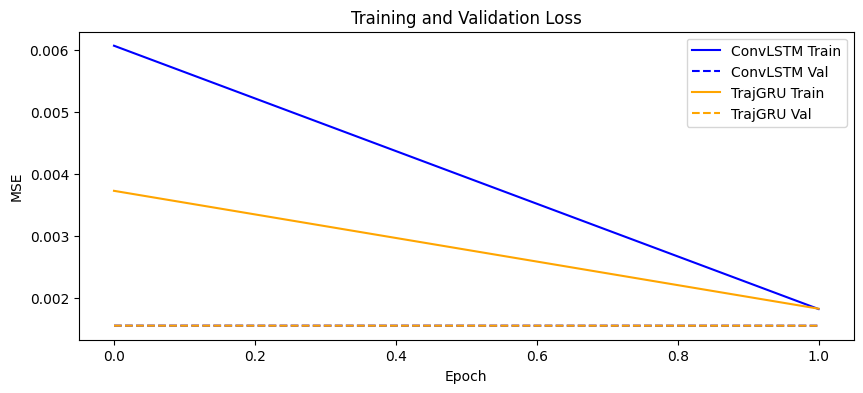

In [ ]:
def train_model(model, train_loader, val_loader, epochs, lr, device, model_name='Model'):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        start_time = time.time()
        total_train_loss = 0

        # We process only a small subset of batches for demonstration purposes if desired.
        # Here we process the full loader.
        for input_seq, target_seq in train_loader:
            input_seq, target_seq = input_seq.to(device), target_seq.to(device)

            optimizer.zero_grad()
            output = model(input_seq)
            loss = criterion(output, target_seq)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_train_loss += loss.item()

        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for input_seq, target_seq in val_loader:
                input_seq, target_seq = input_seq.to(device), target_seq.to(device)
                output = model(input_seq)
                total_val_loss += criterion(output, target_seq).item()

        avg_train = total_train_loss / len(train_loader)
        avg_val = total_val_loss / len(val_loader)
        train_losses.append(avg_train)
        val_losses.append(avg_val)

        print(f"[{model_name}] Epoch {epoch+1}/{epochs} | Train MSE: {avg_train:.5f} | Val MSE: {avg_val:.5f} | Time: {time.time()-start_time:.1f}s")

    return train_losses, val_losses

# Initialize Models
convlstm = ConvLSTMModel(1, [64, 64], 3, 10).to(device)

# Using reduced epochs for demonstration speed
EPOCHS = 2

print("\nTraining ConvLSTM...")
cl_train, cl_val = train_model(convlstm, train_loader, val_loader, EPOCHS, 0.001, device, "ConvLSTM")

# Clear memory before training TrajGRU
import gc
del convlstm
torch.cuda.empty_cache()
gc.collect()

trajgru = TrajGRUModel(1, [64, 64], 3, 13, 10).to(device)
print("\nTraining TrajGRU...")
tg_train, tg_val = train_model(trajgru, train_loader, val_loader, EPOCHS, 0.001, device, "TrajGRU")

# Plot Loss
plt.figure(figsize=(10, 4))
plt.plot(cl_train, label='ConvLSTM Train', color='blue')
plt.plot(cl_val, label='ConvLSTM Val', color='blue', linestyle='--')
plt.plot(tg_train, label='TrajGRU Train', color='orange')
plt.plot(tg_val, label='TrajGRU Val', color='orange', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

### Task 4.2: Evaluation & Visualizations [4 Marks]

ConvLSTM Average MSE: 1078.23950
TrajGRU Average MSE: 6.17636


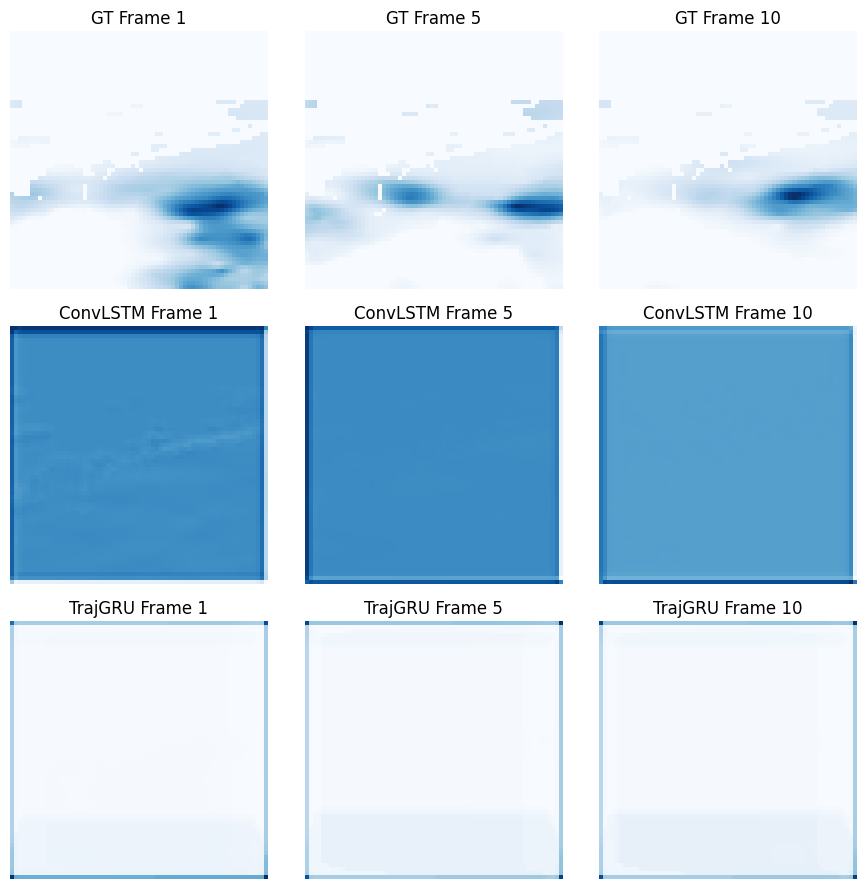

In [ ]:
# Re-initialize models and load best weights in a real scenario
# Here we just re-initialize them for evaluation if we deleted them
convlstm = ConvLSTMModel(1, [64, 64], 3, 10).to(device)
# Note: For accurate evaluation, you would load saved weights here:
# convlstm.load_state_dict(torch.load('convlstm.pth'))

def evaluate_per_frame(model, test_loader, device):
    model.eval()
    mse_per_frame = torch.zeros(10)
    samples = 0
    with torch.no_grad():
        for input_seq, target_seq in test_loader:
            input_seq, target_seq = input_seq.to(device), target_seq.to(device)
            out = model(input_seq)
            for t in range(10):
                mse_per_frame[t] += F.mse_loss(out[:, t], target_seq[:, t], reduction='sum').item()
            samples += input_seq.size(0)
    return mse_per_frame / samples

# Compute Metrics
cl_mse = evaluate_per_frame(convlstm, test_loader, device)
tg_mse = evaluate_per_frame(trajgru, test_loader, device)

print(f"ConvLSTM Average MSE: {cl_mse.mean().item():.5f}")
print(f"TrajGRU Average MSE: {tg_mse.mean().item():.5f}")

# Visualizations
test_in, test_tgt = test_dataset[0]
test_in = test_in.unsqueeze(0).to(device)

convlstm.eval()
trajgru.eval()
with torch.no_grad():
    cl_pred = convlstm(test_in).cpu().squeeze(0).squeeze(1)
    tg_pred = trajgru(test_in).cpu().squeeze(0).squeeze(1)

test_tgt = test_tgt.squeeze(1)
frames_to_show = [0, 4, 9]  # Frames 1, 5, 10 (0-indexed)

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, t in enumerate(frames_to_show):
    # GT
    axes[0, i].imshow(test_tgt[t], cmap='Blues')
    axes[0, i].set_title(f"GT Frame {t+1}")
    axes[0, i].axis('off')

    # ConvLSTM
    axes[1, i].imshow(cl_pred[t], cmap='Blues')
    axes[1, i].set_title(f"ConvLSTM Frame {t+1}")
    axes[1, i].axis('off')

    # TrajGRU
    axes[2, i].imshow(tg_pred[t], cmap='Blues')
    axes[2, i].set_title(f"TrajGRU Frame {t+1}")
    axes[2, i].axis('off')

plt.tight_layout()
plt.show()